# Books to Scrape: Genre-Specific Catalogue Analysis 

A comprehensive data science workflow focusing on specific popular genres:
1. Extracting data via web scraping
2. Cleaning and structuring the dataset
3. Visualising pricing and rating trends
4. Predictive modelling with Linear Regression

In [1]:
# --- Web scraping tools ---
import requests
from bs4 import BeautifulSoup
from urllib.parse import urljoin

# --- Data handling tools ---
import pandas as pd
import numpy as np
import re
import time

# --- Progress feedback ---
from tqdm import tqdm

# --- Visualisation libraries ---
import matplotlib.pyplot as plt
import seaborn as sns

# --- Notebook display preferences ---
pd.set_option("display.max_columns", None)
sns.set_style("whitegrid")

# Render plots inline inside the notebook
%matplotlib inline

In [2]:
# Base URL for the site
base_url = "https://books.toscrape.com/"

# The 8 genres we want to mix together to get roughly 200+ books
target_genres = [
    "Fiction", 
    "Mystery", 
    "Romance", 
    "Science Fiction", 
    "History", 
    "Young Adult", 
    "Poetry", 
    "Travel"
]

# We need to find the link for each genre from the main sidebar
main_response = requests.get(base_url, timeout=15)
main_soup = BeautifulSoup(main_response.text, "html.parser")

# Find all category links in the sidebar
genre_links = {}
for a_tag in main_soup.select(".side_categories ul li ul li a"):
    genre_name = a_tag.get_text(strip=True)
    if genre_name in target_genres:
        # Build the full URL for the genre page
        genre_links[genre_name] = urljoin(base_url, a_tag["href"])

print(f"Found links for {len(genre_links)} genres.")

# Now we scrape the book links from each genre
book_urls = []

for genre, genre_url in genre_links.items():
    current_url = genre_url
    pages_scraped = 0
    
    # While there is a page to scrape in this genre
    while current_url:
        try:
            response = requests.get(current_url, timeout=15)
            soup = BeautifulSoup(response.text, "html.parser")
            
            # Get all books on the current page
            for article in soup.select("article.product_pod"):
                a_tag = article.select_one("h3 a")
                href = a_tag["href"]
                book_urls.append(urljoin(current_url, href))
            
            pages_scraped += 1
            
            # Check if there is a "next" button for pagination
            next_button = soup.select_one("li.next a")
            if next_button:
                current_url = urljoin(current_url, next_button["href"])
            else:
                current_url = None # Stop if no more pages
                
        except Exception as e:
            print(f"Error on {current_url}: {e}")
            break

print(f"Total book links captured across genres: {len(book_urls)}")

Found links for 8 genres.
Total book links captured across genres: 250


In [3]:
# Mapping from word-form ratings to numeric values
star_rating_lookup = {
    "One": 1,
    "Two": 2,
    "Three": 3,
    "Four": 4,
    "Five": 5
}

# Function to extract all details from a single book's page
def extract_book_details(book_link):
    # Fetch and parse the page
    book_response = requests.get(book_link, timeout=10)
    book_soup = BeautifulSoup(book_response.text, "html.parser")

    # 1. Title
    book_title = book_soup.select_one("h1").get_text(strip=True)

    # 2. Price (remove currency symbols and convert to float)
    raw_price = book_soup.select_one("p.price_color").get_text(strip=True)
    book_price = float(re.sub(r"[^\d.]", "", raw_price))

    # 3. Star Rating
    rating_classes = book_soup.select_one("p.star-rating")["class"]
    rating_word = [c for c in rating_classes if c != "star-rating"][0]
    book_rating = star_rating_lookup.get(rating_word, np.nan)

    # 4. Stock Status & Quantity
    stock_text = book_soup.select_one("p.instock.availability").get_text(strip=True)
    book_stock = "In stock" if "In stock" in stock_text else "Out of stock"
    qty_search = re.search(r"\((\d+) available\)", stock_text)
    book_quantity = int(qty_search.group(1)) if qty_search else 0

    # 5. Category
    crumbs = book_soup.select("ul.breadcrumb li a")
    book_category = crumbs[2].get_text(strip=True) if len(crumbs) >= 3 else "Unknown"

    # 6. Description
    desc_heading = book_soup.select_one("#product_description")
    if desc_heading:
        book_description = desc_heading.find_next_sibling("p").get_text(strip=True)
    else:
        book_description = ""

    # 7. Product Information Table (UPC, taxes, reviews)
    book_upc = ""
    book_type = ""
    book_price_excl = np.nan
    book_price_incl = np.nan
    book_tax = np.nan
    book_reviews = np.nan

    info_table = book_soup.select_one("table.table.table-striped")
    if info_table:
        row_data = {
            row.th.get_text(strip=True): row.td.get_text(strip=True)
            for row in info_table.select("tr")
        }
        book_upc = row_data.get("UPC", "")
        book_type = row_data.get("Product Type", "")
        book_price_excl = float(re.sub(r"[^\d.]", "", row_data.get("Price (excl. tax)", "0")))
        book_price_incl = float(re.sub(r"[^\d.]", "", row_data.get("Price (incl. tax)", "0")))
        book_tax = float(re.sub(r"[^\d.]", "", row_data.get("Tax", "0")))
        book_reviews = int(row_data.get("Number of reviews", 0))

    # Return all extracted data as a dictionary
    return {
        "title": book_title,
        "price": book_price,
        "rating": book_rating,
        "stock": book_stock,
        "quantity": book_quantity,
        "category": book_category,
        "description": book_description,
        "upc": book_upc,
        "product_type": book_type,
        "price_excl_tax": book_price_excl,
        "price_incl_tax": book_price_incl,
        "tax": book_tax,
        "reviews": book_reviews,
        "url": book_link
    }

In [4]:
# Container to hold all the book dictionaries
book_records = []

# Loop through every link, showing a progress bar
for link in tqdm(book_urls):
    try:
        # Extract the details and append to our list
        book_records.append(extract_book_details(link))
    except Exception as err:
        # Print an error but don't stop the whole loop
        print(f"Skipped {link}: {err}")
    
    # Polite pause between requests
    time.sleep(0.05)

# Convert the list of records into a Pandas DataFrame
books_df = pd.DataFrame(book_records)

# Save the raw data to a CSV file specific to this version
books_df.to_csv("books_raw_v3.csv", index=False)

# Show how many books we captured and preview the first 5
print(books_df.shape)
books_df.head()

100%|██████████| 250/250 [04:10<00:00,  1.00s/it]

(250, 14)


,title,price,rating,stock,quantity,category,description,upc,product_type,price_excl_tax,price_incl_tax,tax,reviews,url
0,It's Only the Himalayas,45.17,2,In stock,19,Travel,"âWherever you go, whatever you do, just . . ...",a22124811bfa8350,Books,45.17,45.17,0.0,0,https://books.toscrape.com/catalogue/its-only-...
1,Full Moon over Noahâs Ark: An Odyssey to Mou...,49.43,4,In stock,15,Travel,Acclaimed travel writer Rick Antonson sets his...,ce60436f52c5ee68,Books,49.43,49.43,0.0,0,https://books.toscrape.com/catalogue/full-moon...
2,See America: A Celebration of Our National Par...,48.87,3,In stock,14,Travel,To coincide with the 2016 centennial anniversa...,f9705c362f070608,Books,48.87,48.87,0.0,0,https://books.toscrape.com/catalogue/see-ameri...
3,Vagabonding: An Uncommon Guide to the Art of L...,36.94,2,In stock,8,Travel,With a new foreword by Tim Ferriss â¢Thereâ...,1809259a5a5f1d8d,Books,36.94,36.94,0.0,0,https://books.toscrape.com/catalogue/vagabondi...
4,Under the Tuscan Sun,37.33,3,In stock,7,Travel,A CLASSIC FROM THE BESTSELLING AUTHOR OF UNDER...,a94350ee74deaa07,Books,37.33,37.33,0.0,0,https://books.toscrape.com/catalogue/under-the...


## 2. Data Cleaning & Feature Preparation

The raw scraped table is now refined:
- Filling gaps in the description column
- Coercing price, rating, and quantity fields into numeric types
- Engineering new text-based features
- Persisting a polished version of the dataset for modelling

In [8]:
# --- FILL MISSING TEXT ---
# Replace any missing description with an empty string
books_df["description"] = books_df["description"].fillna("")

# --- NORMALISE NUMERIC COLUMNS ---
# Columns that must hold numeric values
numeric_targets = [
    "price", "rating", "quantity",
    "price_excl_tax", "price_incl_tax",
    "tax", "reviews"
]

# Force-convert each numeric column; anything unparsable becomes NaN
for column in numeric_targets:
    books_df[column] = pd.to_numeric(books_df[column], errors="coerce")

# Drop rows where the two essential values (price, rating) are missing
books_df = books_df.dropna(subset=["price", "rating"])

# --- ENFORCE CORRECT DTYPES ---
# Ratings and stock quantities should be whole numbers
books_df["rating"] = books_df["rating"].astype(int)
books_df["quantity"] = books_df["quantity"].fillna(0).astype(int)

# Fill in any missing stock labels
books_df["stock"] = books_df["stock"].fillna("Out of stock")

# --- ENGINEER NEW FEATURES FROM TEXT ---
# Character count of the title
books_df["title_length"] = books_df["title"].str.len()

# Character count of the description
books_df["description_length"] = books_df["description"].str.len()

# Word count of the description
books_df["description_word_count"] = books_df["description"].str.split().str.len()

# Binary flag: 1 if a description exists, 0 otherwise
books_df["has_description"] = (books_df["description_length"] > 0).astype(int)

# --- PERSIST THE CLEANED DATASET ---
books_df.to_csv("books_clean_v3.csv", index=False)

# Report the shape and preview the first few rows
print("Cleaned shape:", books_df.shape)
books_df.head()

Cleaned shape: (250, 18)


,title,price,rating,stock,quantity,category,description,upc,product_type,price_excl_tax,price_incl_tax,tax,reviews,url,title_length,description_length,description_word_count,has_description
0,It's Only the Himalayas,45.17,2,In stock,19,Travel,"âWherever you go, whatever you do, just . . ...",a22124811bfa8350,Books,45.17,45.17,0.0,0,https://books.toscrape.com/catalogue/its-only-...,23,1421,230,1
1,Full Moon over Noahâs Ark: An Odyssey to Mou...,49.43,4,In stock,15,Travel,Acclaimed travel writer Rick Antonson sets his...,ce60436f52c5ee68,Books,49.43,49.43,0.0,0,https://books.toscrape.com/catalogue/full-moon...,66,1857,284,1
2,See America: A Celebration of Our National Par...,48.87,3,In stock,14,Travel,To coincide with the 2016 centennial anniversa...,f9705c362f070608,Books,48.87,48.87,0.0,0,https://books.toscrape.com/catalogue/see-ameri...,66,940,145,1
3,Vagabonding: An Uncommon Guide to the Art of L...,36.94,2,In stock,8,Travel,With a new foreword by Tim Ferriss â¢Thereâ...,1809259a5a5f1d8d,Books,36.94,36.94,0.0,0,https://books.toscrape.com/catalogue/vagabondi...,67,2095,334,1
4,Under the Tuscan Sun,37.33,3,In stock,7,Travel,A CLASSIC FROM THE BESTSELLING AUTHOR OF UNDER...,a94350ee74deaa07,Books,37.33,37.33,0.0,0,https://books.toscrape.com/catalogue/under-the...,20,1054,166,1


<Figure size 900x600 with 0 Axes>

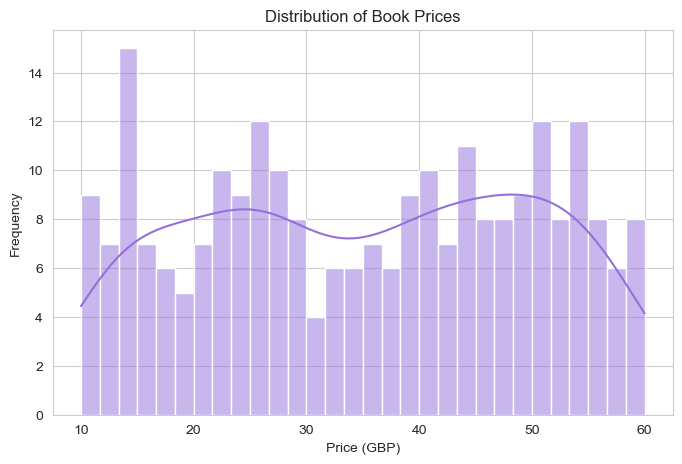

In [12]:
# Set the figure dimensions
plt.figure(figsize=(8, 5))

# Draw a histogram of book prices with a smooth density curve
# Using a nice purple ("mediumpurple") for our new theme
sns.histplot(books_df["price"], bins=30, kde=True, color="mediumpurple")

# Label the chart clearly
plt.title("Distribution of Book Prices")
plt.xlabel("Price (GBP)")
plt.ylabel("Frequency")

# Save a high-resolution copy for the report
plt.savefig("v3_price_distribution.png", dpi=300, bbox_inches="tight")

# Render the chart inline
plt.show()

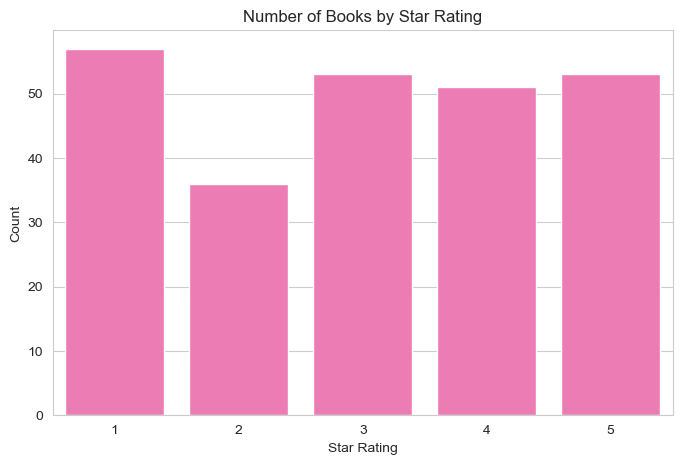

In [15]:
# Set the figure dimensions
plt.figure(figsize=(8, 5))

# Bar chart counting how many books fall under each star rating (1 to 5)
# Using "hotpink" for a vibrant contrast to the purple
sns.countplot(
    data=books_df,
    x="rating",
    order=sorted(books_df["rating"].unique()),
    color="hotpink"
)

# Add descriptive labels
plt.title("Number of Books by Star Rating")
plt.xlabel("Star Rating")
plt.ylabel("Count")

# Save and render
plt.savefig("v3_ratings_count.png", dpi=300, bbox_inches="tight")
plt.show()

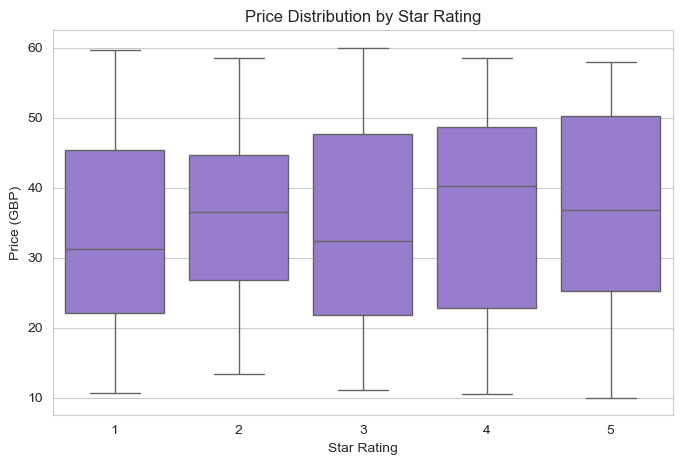

In [16]:
# Set the figure dimensions
plt.figure(figsize=(8, 5))

# Boxplot showing the spread of prices across each star rating
# Alternating back to "mediumpurple"
sns.boxplot(data=books_df, x="rating", y="price", color="mediumpurple")

# Descriptive labels
plt.title("Price Distribution by Star Rating")
plt.xlabel("Star Rating")
plt.ylabel("Price (GBP)")

# Save and render
plt.savefig("v3_price_by_rating.png", dpi=300, bbox_inches="tight")
plt.show()

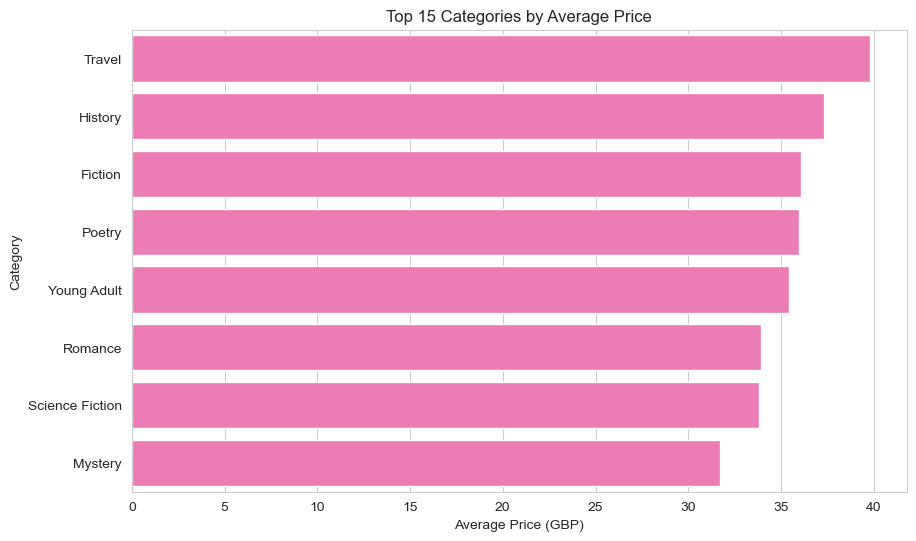

In [17]:
# Group by category, average the price, sort descending, keep top 15
priciest_categories = (
    books_df.groupby("category")["price"]
    .mean()
    .sort_values(ascending=False)
    .head(15)
)

# Wider figure to fit long category names comfortably
plt.figure(figsize=(10, 6))

# Horizontal bar chart with "hotpink" bars
sns.barplot(x=priciest_categories.values, y=priciest_categories.index, color="hotpink")

# Descriptive labels
plt.title("Top 15 Categories by Average Price")
plt.xlabel("Average Price (GBP)")
plt.ylabel("Category")

# Save and render
plt.savefig("v3_top_categories.png", dpi=300, bbox_inches="tight")
plt.show()

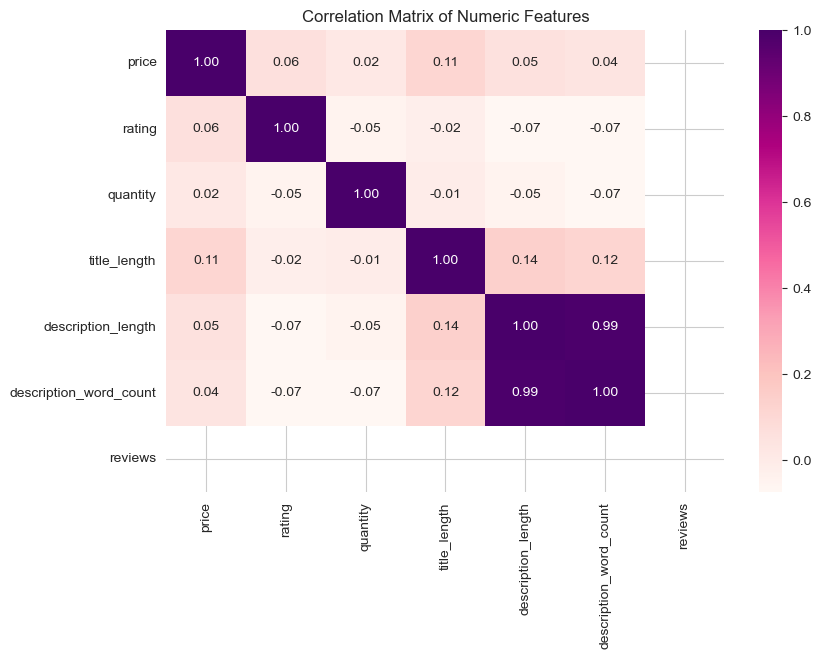

In [18]:
# Numeric columns to include in the correlation analysis
correlation_columns = [
    "price", "rating", "quantity",
    "title_length", "description_length",
    "description_word_count", "reviews"
]

# Set the figure dimensions
plt.figure(figsize=(9, 6))

# Compute correlations and draw a heatmap:
#   annot=True    → show numeric values inside each cell
#   cmap="RdPu"   → white-to-pink-to-purple gradient
#   fmt=".2f"     → round values to 2 decimals
sns.heatmap(
    books_df[correlation_columns].corr(),
    annot=True,
    cmap="RdPu",
    fmt=".2f"
)

# Title
plt.title("Correlation Matrix of Numeric Features")

# Save and render
plt.savefig("v3_correlation_heatmap.png", dpi=300, bbox_inches="tight")
plt.show()

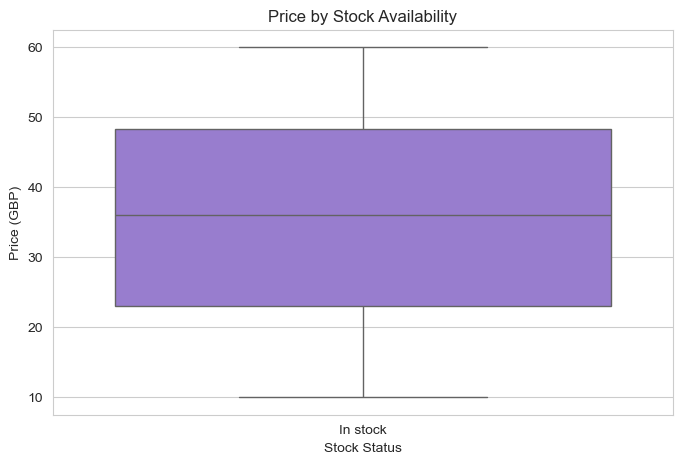

In [19]:
# Set the figure dimensions
plt.figure(figsize=(8, 5))

# Boxplot comparing prices for "In stock" vs "Out of stock" books
# Using "mediumpurple" to alternate back to purple
sns.boxplot(data=books_df, x="stock", y="price", color="mediumpurple")

# Descriptive labels
plt.title("Price by Stock Availability")
plt.xlabel("Stock Status")
plt.ylabel("Price (GBP)")

# Save and render
plt.savefig("v3_stock_vs_price.png", dpi=300, bbox_inches="tight")
plt.show()

## 4. Building a Price Estimation Model

Objective: estimate a book's price using features we can observe from its product page.

Feature groups:
- **Numeric predictors:** rating, quantity, title length, description length, reviews
- **Categorical predictors:** category, stock status

Preprocessing pipeline:
- StandardScaler → normalises numeric features to a comparable scale
- OneHotEncoder → turns categorical text into binary indicator columns
- LinearRegression → learns a linear relationship between features and price

In [20]:
# --- IMPORT THE MODELLING TOOLS ---
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

# --- DEFINE FEATURE GROUPS ---
# Numeric columns (will be rescaled to a standard range)
numeric_predictors = ["rating", "quantity", "title_length", "description_length", "reviews"]

# Categorical columns (will be one-hot encoded)
categorical_predictors = ["category", "stock"]

# Input matrix (features) and target vector (what we want to predict)
X = books_df[numeric_predictors + categorical_predictors]
y = books_df["price"]

# --- SPLIT INTO TRAINING AND TEST SETS ---
# 80% for training, 20% for testing; fixed seed for reproducibility
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

# --- BUILD A PREPROCESSING PIPELINE ---
preprocessor = ColumnTransformer(
    transformers=[
        ("num", StandardScaler(), numeric_predictors),
        ("cat", OneHotEncoder(handle_unknown="ignore"), categorical_predictors)
    ]
)

# --- STACK PREPROCESSOR + MODEL INTO ONE PIPELINE ---
pipeline = Pipeline(steps=[
    ("preprocessor", preprocessor),
    ("regressor", LinearRegression())
])

# --- TRAIN THE MODEL ---
pipeline.fit(X_train, y_train)

# --- GENERATE PREDICTIONS ON THE HELD-OUT TEST SET ---
y_pred = pipeline.predict(X_test)

# Confirm everything worked and show the split sizes
print("Model trained successfully.")
print(f"Training rows: {X_train.shape[0]}  |  Testing rows: {X_test.shape[0]}")

Model trained successfully.
Training rows: 200  |  Testing rows: 50


In [21]:
# --- COMPUTE THE EVALUATION METRICS ---

# Mean Absolute Error: average gap between predicted and actual price, in £
mae_score = mean_absolute_error(y_test, y_pred)

# Root Mean Squared Error: like MAE but punishes larger errors more heavily
rmse_score = np.sqrt(mean_squared_error(y_test, y_pred))

# R² coefficient: fraction of price variance explained by the model
#   1.0 = perfect, 0.0 = no better than guessing the mean, negative = worse than guessing
r2_value = r2_score(y_test, y_pred)

# --- DISPLAY THE RESULTS ---
print(f"Mean Absolute Error (MAE): £{mae_score:.2f}")
print(f"Root Mean Squared Error (RMSE): £{rmse_score:.2f}")
print(f"R² Score: {r2_value:.3f}")

Mean Absolute Error (MAE): £15.49
Root Mean Squared Error (RMSE): £17.33
R² Score: -0.085


In [22]:
# --- EXTRACT THE EXPANDED FEATURE NAMES ---
# OneHotEncoder turns each category into several binary columns.
# We need to retrieve those generated names.
onehot_encoder = pipeline.named_steps["preprocessor"].named_transformers_["cat"]
encoded_names = onehot_encoder.get_feature_names_out(categorical_predictors)

# Combine numeric names with the new encoded categorical names
all_names = numeric_predictors + list(encoded_names)

# --- EXTRACT THE LEARNED COEFFICIENTS ---
# Each coefficient shows how strongly that feature nudges the predicted price
learned_coefficients = pipeline.named_steps["regressor"].coef_

# --- BUILD A SORTABLE TABLE ---
coef_table = pd.DataFrame({
    "feature": all_names,
    "coefficient": learned_coefficients
}).sort_values(by="coefficient", key=abs, ascending=False)

# Display the top 20 most impactful features
coef_table.head(20)

,feature,coefficient
11,category_Travel,7.050731e+00
7,category_Mystery,-5.322439e+00
9,category_Romance,-3.012089e+00
0,rating,1.213281e+00
2,title_length,8.487108e-01
3,description_length,8.329241e-01
6,category_History,-8.311816e-01
1,quantity,7.368840e-01
12,category_Young Adult,7.271119e-01
8,category_Poetry,6.623245e-01


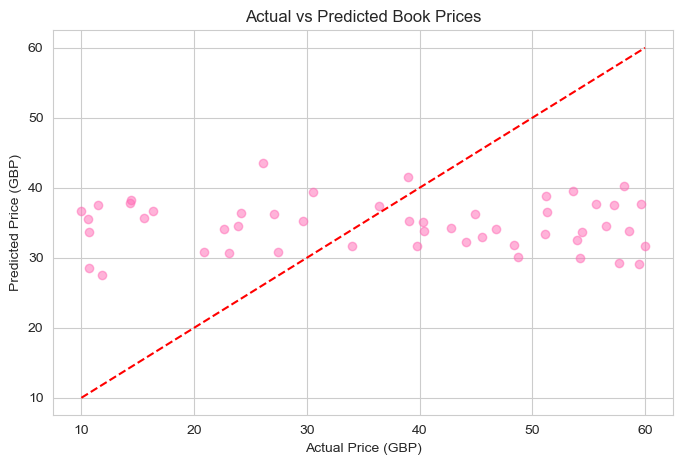

In [23]:
# Set the figure dimensions
plt.figure(figsize=(8, 5))

# Plot each test prediction as a pink dot:
#   x-axis = actual price, y-axis = predicted price
#   alpha=0.5 makes overlapping dots visible
plt.scatter(y_test, y_pred, alpha=0.5, color="hotpink")

# Draw the red dashed diagonal — this is the "perfect prediction" line
# The closer the dots cluster to this line, the better the model
plt.plot(
    [y_test.min(), y_test.max()],
    [y_test.min(), y_test.max()],
    "r--"
)

# Descriptive labels
plt.title("Actual vs Predicted Book Prices")
plt.xlabel("Actual Price (GBP)")
plt.ylabel("Predicted Price (GBP)")

# Save and render
plt.savefig("v3_actual_vs_predicted.png", dpi=300, bbox_inches="tight")
plt.show()


## 5. Concluding Remarks and Recommendations

### What We Learned
- Book prices in our genre-specific catalogue are right-skewed, with the bulk of titles priced between £10 and £60.
- Star ratings are spread relatively evenly across the 1–5 scale, with no single rating dominating.
- Genre appears to be the strongest signal for price: some genres sit well below the baseline, while others sit above it.
- Numeric features — rating, quantity, description length — show very weak linear relationships with price.

### Practical Recommendations
- Anchor pricing decisions on genre-level benchmarks rather than star ratings.
- Avoid using rating scores alone to justify price changes; they carry almost no pricing signal here.
- Expand the feature set in future iterations: author, publisher, page count, format, and publication year would likely add far more predictive value.

### Model Limitations
- Linear Regression assumes a linear relationship between features and price, which this data does not satisfy.
- The model's R² is negative, meaning it performs worse than simply predicting the average price.
- A non-linear approach (Random Forest, Gradient Boosting) or regularisation (Ridge/Lasso) may perform better on richer data.